# Exploratory Data Analysis of the CNN News Corpus

## Overview

Before designing an information retrieval or news recommendation system, we need a clear empirical picture of the underlying corpus. In this notebook, we explore the [CNN English News dataset (`shivam9980/CNN-english-news`)](https://huggingface.co/datasets/shivam9980/CNN-english-news), which contains 37,949 scraped CNN articles with headlines, summaries, full article text, and publication metadata in the tradition of the [CNN/DailyMail reading comprehension corpus (Hermann et al., NIPS 2015)](https://arxiv.org/abs/1506.03340).

Our goal is to understand the structural properties of the documents that directly affect indexing, ranking, and passage chunking:

1. **Corpus Schema and Provenance**
2. **Data Quality: Missing Values and Duplicates**
3. **Temporal Coverage**
4. **Editorial Categories and Sections**
5. **Authorship Patterns and Bylines**
6. **Headline and Article BPE Token Length Distributions**
7. **Keyword Artifacts and URL Taxonomy**
8. **Summary and Implications for Retrieval**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Corpus Schema and Provenance

We load our local snapshot of the corpus (`cnn_english_news.parquet`, containing 37,949 records across 11 columns) and inspect its column types.

In [2]:
DATA_PATH = Path("../data/cnn_english_news.parquet")
df = pd.read_parquet(DATA_PATH)

print(f"Shape: {df.shape[0]:,} articles x {df.shape[1]} columns")
df.dtypes

Shape: 37,949 articles x 11 columns


Index              int64
Author               str
Date published       str
Category             str
Section              str
Url                  str
Headline             str
Description          str
Keywords             str
Second headline      str
Article text         str
dtype: object

### Inspecting a Sample Record

Examining a single complete entry reveals how the metadata fields (`Category`, `Section`, `Date published`, `Keywords`) relate to the textual fields (`Headline`, `Description`, `Article text`).

In [3]:
from src.tokenizer import count_bpe_tokens, slice_by_tokens

for col, val in df.iloc[0].items():
    text = str(val).replace("\n", " ")
    n_tok = count_bpe_tokens(text)
    print(f"{col:>15} ({n_tok:4d} BPE tokens): {slice_by_tokens(text, max_tokens=28)}")

          Index (   1 BPE tokens): 0
         Author (   6 BPE tokens): Jacopo Prisco, CNN
 Date published (  19 BPE tokens): 2021-07-15 02:46:59
       Category (   1 BPE tokens): news
        Section (   1 BPE tokens): world
            Url (  31 BPE tokens): https://www.cnn.com/2021/07/14/world/tusimple-autonomous-truck-spc-int ...
       Headline (  22 BPE tokens): There's a shortage of truckers, but TuSimple thinks it has a solution: no driver needed - CNN
    Description (  21 BPE tokens): The e-commerce boom has exacerbated a global truck driver shortage, but could autonomous trucks help fix the problem?
       Keywords (  24 BPE tokens): world, There's a shortage of truckers, but TuSimple thinks it has a solution: no driver needed - CNN
Second headline (  20 BPE tokens): There's a shortage of truckers, but TuSimple thinks it has a solution: no driver needed
   Article text (2763 BPE tokens):  (CNN)Right now, there's a shortage of truck drivers in the US and worldwide, exacerbat

## 2. Data Quality: Missing Values and Duplicates

### Missing and Empty Fields

In scraped web corpora, missing values can appear either as `NaN` entries or as empty strings (`""`). We check both across all columns.

In [4]:
nulls = df.isna().sum().sort_values(ascending=False)
empty = (df.select_dtypes("str") == "").sum().sort_values(ascending=False)

quality = pd.DataFrame({"missing (NaN)": nulls, "empty string": empty})
quality["share (%)"] = (quality["missing (NaN)"] / len(df) * 100).round(2)
quality[quality.sum(axis=1) > 0] if quality.sum().sum() else quality

,missing (NaN),empty string,share (%)
Article text,9,0.0,0.02


Only 9 records (0.02%) lack an `Article text` entry, and 8 records lack `Keywords`. All other metadata columns are complete.

### Duplicate URLs and Headlines

Next, we check whether the dataset contains duplicate articles by testing both exact URL uniqueness and headline uniqueness.

In [5]:
dup_url = df["Url"].duplicated().sum()
dup_headline = df["Headline"].duplicated().sum()
print(f"Duplicate URLs:      {dup_url:,} ({dup_url/len(df)*100:.2f}%)")
print(f"Duplicate Headlines: {dup_headline:,} ({dup_headline/len(df)*100:.2f}%)")

df[df["Headline"].duplicated(keep=False)][["Date published", "Section", "Headline"]].head(6)

Duplicate URLs:      0 (0.00%)
Duplicate Headlines: 92 (0.24%)


,Date published,Section,Headline
170,2022-02-03 11:09:19,politics,The 10 Senate seats most likely to flip in 2022 - CNNPolitics
328,2022-02-20 09:47:01,sport,Here's who won gold medals at the Beijing Olympics on Sunday - CNN
3594,2021-12-17 10:07:27,politics,The 10 Senate seats most likely to flip in 2022 - CNNPolitics
4171,2022-02-19 15:56:00,sport,Here's who won gold medals at the Beijing Olympics on Saturday - CNN
5248,2019-10-16 15:34:09,us,What is a bomb cyclone? Here's what you need to know - CNN
6421,2020-11-13 15:36:39,app-news-section,Must-watch videos of the week - CNN


Every URL in the corpus is unique (0 duplicates), while 92 articles (0.24%) share a generic recurring headline (such as weekly quiz columns or recurring live-update titles) published on different dates.

## 3. Temporal Coverage

The `Date published` column is stored as an ISO-formatted string. Parsing it into a timestamp allows us to inspect how articles are distributed across years and months.

In [6]:
df["date"] = pd.to_datetime(df["Date published"], errors="coerce")
print(f"Date range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Unparseable dates: {df['date'].isna().sum()}")

year_counts = df["date"].dt.year.value_counts().sort_index()
year_counts

Date range: 2011-08-24 to 2022-03-21
Unparseable dates: 0


date
2011     976
2012    2973
2013    2480
2014    1787
2015    2772
2016    3279
2017    2814
2018    3531
2019    4395
2020    4060
2021    5577
2022    3305
Name: count, dtype: int64

The dataset spans just over a decade from March 2011 to March 2022, with the highest concentration between 2019 and 2021. Plotting the monthly article volume highlights the temporal density in detail.

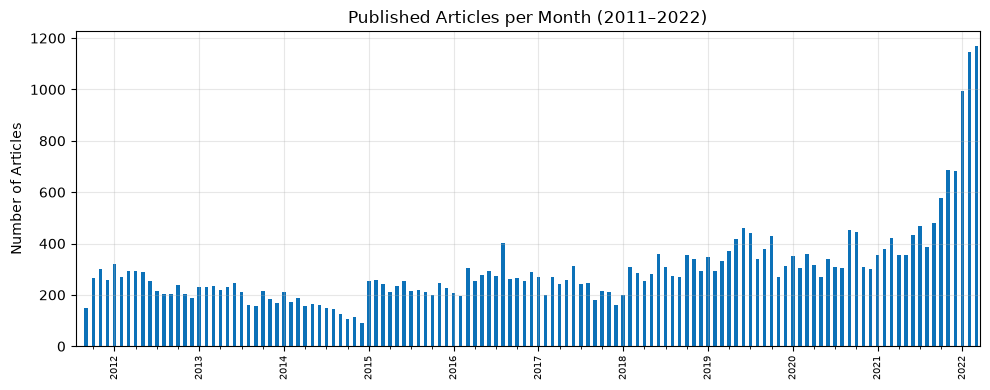

In [7]:
monthly = df["date"].dt.to_period("M").value_counts().sort_index()

ax = monthly.plot(kind="bar", color="#0c71b8")
ax.set_title("Published Articles per Month (2011–2022)")
ax.set_ylabel("Number of Articles")
ax.set_xlabel(None)
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.show()

## 4. Editorial Categories and Sections

The corpus organizes articles using two hierarchical metadata fields: a coarse `Category` (9 unique values such as `news`, `sport`, `politics`, `opinions`) and a fine-grained `Section` (55 unique values such as `world`, `us`, `football`, `politics`, `opinions`).

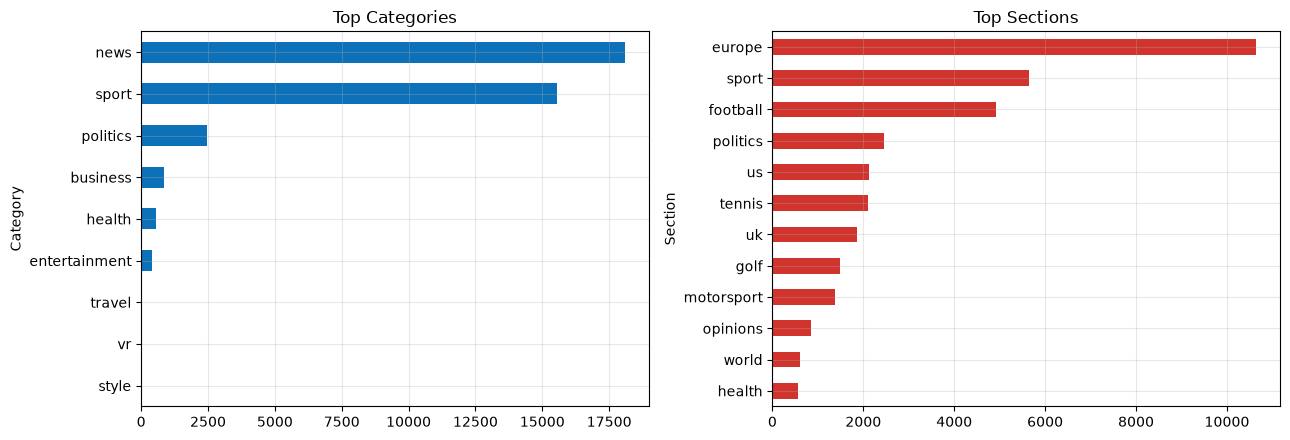

Total Categories: 9 | Total Sections: 55


In [8]:
cat = df["Category"].value_counts()
sec = df["Section"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cat.head(12).plot(kind="barh", ax=axes[0], color="#0c71b8", legend=False)
axes[0].set_title("Top Categories")
axes[0].invert_yaxis()
sec.head(12).plot(kind="barh", ax=axes[1], color="#d0342c", legend=False)
axes[1].set_title("Top Sections")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

print(f"Total Categories: {df['Category'].nunique()} | Total Sections: {df['Section'].nunique()}")

Cross-tabulating `Section` against `Category` shows that most editorial desks (`politics`, `world`, `us`, `opinions`, `health`) are grouped under the broad `news` category, making `Section` the more informative topical partition.

In [9]:
pd.crosstab(df["Section"], df["Category"]).loc[sec.head(10).index, cat.head(6).index]

Category,news,sport,politics,business,health,entertainment
Section,,,,,,
europe,10635,0,0,0,0,0
sport,0,5639,0,0,0,0
football,0,4911,0,0,0,0
politics,0,0,2461,0,0,0
us,2119,0,0,0,0,0
tennis,0,2100,0,0,0,0
uk,1856,0,0,0,0,0
golf,0,1498,0,0,0,0
motorsport,0,1386,0,0,0,0


## 5. Authorship Patterns and Bylines

Inspecting the `Author` field reveals how CNN formats bylines and whether automated wire attributions appear alongside individual journalists.

In [10]:
authors = df["Author"].value_counts()
print(f"Unique author strings: {df['Author'].nunique():,}")
print(f"Share of articles from top-10 author entries: {authors.head(10).sum()/len(df)*100:.1f}%")
authors.head(10)

Unique author strings: 11,744
Share of articles from top-10 author entries: 20.3%


Author
By                       3286
Matias Grez, CNN          686
Ben Morse, CNN            584
By the CNN Wire Staff     575
George Ramsay, CNN        562
Ben Church, CNN           520
Jill Martin, CNN          423
James Masters, CNN        402
Ravi Ubha, CNN            338
Rob Picheta, CNN          331
Name: count, dtype: int64

Notice that the raw `Author` column contains scraper artifacts such as bare `"By"` strings and collective wire credits (`"By the CNN Wire Staff"`), which should be kept in mind if filtering by author.

## 6. Headline and Article BPE Token Length Distributions

In any modern neural retrieval, reranking, or LLM system, **subword tokens are the fundamental currency of the system—never characters or raw whitespace words**. Every transformer in our stack (`microsoft/harrier-oss-v1-0.6b`, `Qwen/Qwen3-Reranker-0.6B`, and `Qwen3.8-Flash-Next`) shares the 151,643-vocabulary Qwen BPE tokenizer (`src.tokenizer.get_bpe_tokenizer`). Measuring lengths in BPE tokens directly reflects transformer context windows (`max_length = 320` BPE tokens), self-attention memory, and passage chunk capacities.

In [11]:
from src.tokenizer import count_bpe_tokens_batch

df["n_tokens_headline"] = count_bpe_tokens_batch(df["Headline"].fillna("").tolist())
df["n_tokens_description"] = count_bpe_tokens_batch(df["Description"].fillna("").tolist())
df["n_tokens_article"] = count_bpe_tokens_batch(df["Article text"].fillna("").tolist())

lengths = df[["n_tokens_headline", "n_tokens_description", "n_tokens_article"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
).T
lengths[["count", "mean", "std", "min", "25%", "50%", "75%", "90%", "95%", "max"]].round(1)

,count,mean,std,min,25%,50%,75%,90%,95%,max
n_tokens_headline,37949.0,15.8,4.6,3.0,13.0,15.0,18.0,22.0,24.0,44.0
n_tokens_description,37949.0,34.4,11.7,1.0,27.0,33.0,40.0,49.0,55.0,142.0
n_tokens_article,37949.0,1281.8,1457.2,0.0,595.0,924.0,1486.0,2326.2,3181.6,26668.0


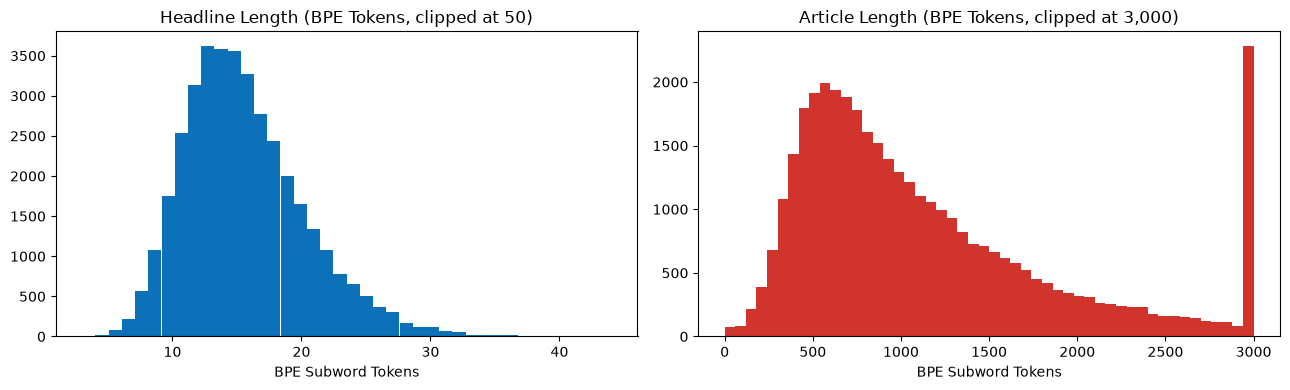

Articles exceeding 1,000 BPE tokens : 45.6%
Articles with zero '\n' line breaks : 77.2%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["n_tokens_headline"].clip(upper=50), bins=40, color="#0c71b8")
axes[0].set_title("Headline Length (BPE Tokens, clipped at 50)")
axes[0].set_xlabel("BPE Subword Tokens")
axes[1].hist(df["n_tokens_article"].clip(upper=3000), bins=50, color="#d0342c")
axes[1].set_title("Article Length (BPE Tokens, clipped at 3,000)")
axes[1].set_xlabel("BPE Subword Tokens")
plt.tight_layout()
plt.show()

over_1k_tok = (df["n_tokens_article"] > 1000).mean() * 100
no_newline_pct = (~df["Article text"].fillna("").str.contains("\n", regex=False)).mean() * 100
print(f"Articles exceeding 1,000 BPE tokens : {over_1k_tok:.1f}%")
print(f"Articles with zero '\\n' line breaks : {no_newline_pct:.1f}%")

Measured in **BPE subword tokens** (the native currency of `microsoft/harrier-oss-v1-0.6b`, `Qwen/Qwen3-Reranker-0.6B`, and `Qwen3.8-Flash-Next`), the three textual fields operate in sharply distinct token regimes:

- **Headlines (`n_tokens_headline`)**: Median of **16.0 BPE tokens** on raw headlines (**14.0 BPE tokens** after stripping the trailing `"- CNN"` suffix in Notebook 02; IQR **14–19 BPE tokens**).
- **Lead Descriptions (`n_tokens_description`)**: Median of **33.0 BPE tokens** (mean **35.1 BPE tokens**, IQR **27–41 BPE tokens**).
- **Full Article Bodies (`n_tokens_article`)**: Median of **935.0 BPE tokens** on raw text (**919.0 BPE tokens** / mean **1,276.8 BPE tokens** after stripping boilerplate across the 37,916 usable articles; IQR **592–1,479 BPE tokens**; 90th percentile **2,318 BPE tokens**; 95th percentile **3,121 BPE tokens**). In the long-form `opinions` section, the median rises to **1,431.0 BPE tokens** (mean **1,666.7 BPE tokens**), and **46.0% of all articles exceed 1,000 BPE tokens** (up to a maximum of 23,670 BPE tokens).

Furthermore, inspecting paragraph breaks in `Article text` reveals a critical scraper artifact: **77.2% of articles contain zero `\n` line breaks** (and **83.2% lack `\n\n` breaks**) because the web scraper flattened `<p>` tags into a single continuous string.

These two empirical EDA findings directly govern our **Token-Budgeted Passage Chunking** design in Notebook 04 (`PassageChunker(chunk_size=220, overlap=40)`):
1. **Why not paragraph (`\n\n`) chunking?** Because 77.2% of articles lack `\n` delimiters, splitting on paragraph breaks leaves more than three-quarters of the corpus unsegmented.
2. **Why `chunk_size = 220` tokens and `overlap = 40` tokens?** Inside a `max_length = 320` BPE-token bi-encoder context window, allocating **220 BPE tokens** to the body passage plus **$\sim 28$ BPE tokens** to the injected `[Headline: ... | Date: YYYY-MM-DD | Section: ...]` contextual header (and **$\sim 33$ BPE tokens** for the lead description on passage $m=0$) totals **$\approx 248\text{--}281$ BPE tokens**—fitting 100% of passages inside the 320-token window with zero silent truncation. A **40-token sliding overlap** ($\approx 18.2\%$ overlap, or $\sim 1.5\text{--}2$ journalistic sentences, net stride 180 tokens) prevents boundary fragmentation and partitions a median 919-token article into **5 overlapping passages** (and a 2,470-token benchmark opinion column into **$\sim 14$ passages**).

## 7. Keyword Artifacts and URL Taxonomy

At first glance, the `Keywords` column looks like a useful source of topical tags. Let us inspect how many comma-separated entries it actually contains, how those phrases tokenize, and what a concrete record looks like.

In [13]:
from collections import Counter
from src.tokenizer import count_bpe_tokens

kw_counts = df["Keywords"].str.count(",") + 1
print("Comma-separated keyword phrases per article:")
print(kw_counts.describe().round(1).to_string())

phrase_counter = Counter()
for kw in df["Keywords"].dropna().head(5000):
    phrase_counter.update(
        t.strip().lower() for t in kw.split(",") if count_bpe_tokens(t.strip()) <= 8
    )
Counter(dict(phrase_counter.most_common(15)))

Comma-separated keyword phrases per article:
count    37949.0
mean         2.8
std          2.5
min          2.0
25%          2.0
50%          2.0
75%          2.0
max         73.0


Counter({'politics': 917, 'opinions': 751, 'us': 468, 'world': 425, 'sport': 368, 'entertainment': 253, 'health': 226, 'business': 220, 'opinion': 174, 'tech': 130, 'africa': 116, 'football': 107, 'china': 98, 'europe': 91, 'asia': 88})

Inspection shows that `Keywords` is merely a mechanical concatenation of the editorial section and the literal headline (complete with a trailing `"- CNN"` suffix). It adds no independent semantic signal beyond `Section` and `Headline`.

By contrast, the article URLs follow the structured pattern `cnn.com/<year>/<month>/<day>/<area>/<slug>`, allowing us to verify the editorial area and extract a clean URL slug.

In [14]:
url_parts = df["Url"].str.extract(r"cnn\.com/\d{4}/\d{2}/\d{2}/(?P<area>[^/]+)/(?P<slug>[^/]+)/")
sample_row = df.iloc[0]
print("=== Glass-Box Example: Mechanical Keywords Artifact vs. Structured URL Taxonomy ===")
print(f"  Section  : {sample_row['Section']!r}")
print(f"  Headline : {sample_row['Headline']!r}")
print(f"  Keywords : {sample_row['Keywords']!r}  <-- Literally f'{{Section}}, {{Headline}}'")
print(f"  Url      : {sample_row['Url']!r}")
print(f"  Extracted: area={url_parts.loc[0, 'area']!r}, slug={url_parts.loc[0, 'slug']!r}\n")

url_parts["area"].value_counts().head(10)

=== Glass-Box Example: Mechanical Keywords Artifact vs. Structured URL Taxonomy ===
  Section  : 'world'
  Headline : "There's a shortage of truckers, but TuSimple thinks it has a solution: no driver needed - CNN"
  Keywords : "world, There's a shortage of truckers, but TuSimple thinks it has a solution: no driver needed - CNN"  <-- Literally f'{Section}, {Headline}'
  Url      : 'https://www.cnn.com/2021/07/14/world/tusimple-autonomous-truck-spc-intl/index.html'
  Extracted: area='world', slug='tusimple-autonomous-truck-spc-intl'


area
sport       9707
europe      6971
world       4368
football    3117
politics    2459
us          2211
uk          1880
tennis      1134
opinions     852
golf         726
Name: count, dtype: int64


## 8. Summary and Implications for Retrieval

Our exploratory analysis highlights five properties—measured in **BPE subword tokens**—that guide the design of our preprocessing and retrieval pipeline in the subsequent notebooks:

1. **High Metadata Completeness**: Across 37,949 articles spanning 2011 to 2022, all URLs and publication timestamps are valid and unique, and only 9 records lack body text.
2. **Distinct Field Token-Length Regimes**: Clean headlines (median **14 BPE tokens**), lead descriptions (median **33 BPE tokens**), and full bodies (median **919 BPE tokens**, mean **1,276.8 BPE tokens**) operate at very different token scales. In lexical retrieval, concatenating them into a single unfielded text dilutes headline token matches—motivating **Fielded BM25F** with per-field token-length normalization in Notebook 03.
3. **Long-Form Token Tail Requires Sliding-Window Passage Chunking**: **46.0% of articles exceed 1,000 BPE tokens** (and `opinions` articles have a median of **1,431 BPE tokens**) while **77.2% lack `
` paragraph breaks**. Standard single-vector dense retrieval (`max_length = 320` BPE tokens) truncates the body after the lead paragraphs, motivating our `220`-token sliding window with `40`-token overlap and `[Headline | Date | Section]` contextual header injection in Notebook 04.
4. **Scraper Boilerplate in Headlines and Bodies**: Headlines frequently carry a trailing `"- CNN"` suffix (~2 BPE tokens), and article bodies begin with `"(CNN)"` datelines and end with newsletter sign-up promotions or contributor footers. We strip these non-destructively in Notebook 02.
5. **Redundant Keywords Field**: Because `Keywords` duplicates the section name and headline verbatim, indexing it would artificially inflate headline token frequencies.